# 🧠 고전 CNN 모델 실습: LeNet-5 / VGG16

이번 노트북에서는 고전적인 CNN 모델 2종을 실습합니다.

1. **LeNet-5** — MNIST 직접 학습 및 평가
2. **VGG16** — ImageNet 사전학습 가중치로 예측 실습

모든 모델의 파라미터 수를 비교하고, 구조를 살펴봅니다.

In [1]:
import os, sys
os.environ['KERAS_HOME'] = '/Users/jungseok/orca/workspaces/solucionemos-vault/wt04/reports/lms-tg11308/cache/keras'
os.environ['MPLCONFIGDIR'] = '/Users/jungseok/orca/workspaces/solucionemos-vault/wt04/reports/lms-tg11308/cache/matplotlib'

import tensorflow as tf
# Apple Silicon 16GB RAM 고부하 환경을 위한 스레드 상한 제어 (Coordinator 지침)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(2)

from tensorflow.keras import layers, models, datasets, utils
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import matplotlib.pyplot as plt

print('Python 실행기:', sys.executable)
print('TensorFlow version:', tf.__version__)
print('Keras version:', tf.keras.__version__)


Python 실행기: /Users/jungseok/orca/workspaces/solucionemos-vault/wt04/reports/lms-tg11308/env/bin/python
TensorFlow version: 2.21.0
Keras version: 3.15.1


## [1] LeNet-5 스타일 CNN 구현 및 MNIST 학습

### 1.1 LeNet-5 아키텍처 개요 및 설계 원리
- **발표 연도**: 1998년 (Yann LeCun et al., "Gradient-Based Learning Applied to Document Recognition")
- **설계 목적**: 우편번호 및 은행 수표의 손글씨 숫자 자동 인식
- **핵심 구조 및 계층별 역할**:
  1. **입력층**: $28 \times 28 \times 1$ 크기의 단일 채널(흑백) 손글씨 이미지
  2. **C1 (합성곱층)**: 6개의 $5 \times 5$ 필터, `padding='same'`, 활성화 함수 `tanh` $\rightarrow$ 피처맵 크기 $28 \times 28 \times 6$
  3. **S2 (서브샘플링/풀링층)**: $2 \times 2$ `AveragePooling2D` $\rightarrow$ 피처맵 크기 $14 \times 14 \times 6$ (공간 해상도 절반 축소)
  4. **C3 (합성곱층)**: 16개의 $5 \times 5$ 필터, `padding='valid'`, 활성화 함수 `tanh` $\rightarrow$ 피처맵 크기 $10 \times 10 \times 16$
  5. **S4 (서브샘플링/풀링층)**: $2 \times 2$ `AveragePooling2D` $\rightarrow$ 피처맵 크기 $5 \times 5 \times 16$
  6. **Flatten**: $5 \times 5 \times 16 = 400$ 차원의 1차원 벡터로 변환
  7. **C5/F6 (완전연결층)**: 120개 뉴런, `tanh`
  8. **F7 (완전연결층)**: 84개 뉴런, `tanh`
  9. **출력층 (Output)**: 10개 뉴런, `softmax` (숫자 0~9 확률 분포 출력)
- **현대 CNN과의 차이점**:
  - 현대에는 `ReLU` 활성화 함수와 `MaxPooling`을 주로 사용하나, LeNet-5 원형은 `tanh`와 `AveragePooling`을 사용함.

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print('Train:', x_train.shape, ' Test:', x_test.shape)

Train: (60000, 28, 28, 1)  Test: (10000, 28, 28, 1)


In [3]:
def build_lenet5():
    model = models.Sequential([
        layers.Conv2D(6, (5,5), activation='tanh', input_shape=(28,28,1), padding='same'),
        layers.AveragePooling2D(pool_size=(2,2)),
        layers.Conv2D(16, (5,5), activation='tanh'),
        layers.AveragePooling2D(pool_size=(2,2)),
        layers.Flatten(),
        layers.Dense(120, activation='tanh'),
        layers.Dense(84, activation='tanh'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

lenet5 = build_lenet5()
lenet5.summary()

/Users/jungseok/orca/workspaces/solucionemos-vault/wt04/reports/lms-tg11308/env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = lenet5.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/5


422/422 - 21s - 51ms/step - accuracy: 0.8976 - loss: 0.3562 - val_accuracy: 0.9625 - val_loss: 0.1401


Epoch 2/5


422/422 - 23s - 53ms/step - accuracy: 0.9581 - loss: 0.1384 - val_accuracy: 0.9723 - val_loss: 0.0960


Epoch 3/5


422/422 - 19s - 45ms/step - accuracy: 0.9723 - loss: 0.0913 - val_accuracy: 0.9810 - val_loss: 0.0725


Epoch 4/5


422/422 - 34s - 81ms/step - accuracy: 0.9794 - loss: 0.0689 - val_accuracy: 0.9833 - val_loss: 0.0602


Epoch 5/5


422/422 - 21s - 50ms/step - accuracy: 0.9829 - loss: 0.0547 - val_accuracy: 0.9797 - val_loss: 0.0645


In [5]:
test_loss, test_acc = lenet5.evaluate(x_test, y_test, verbose=0)
print(f"LeNet-5 테스트 정확도: {test_acc:.4f}")

LeNet-5 테스트 정확도: 0.9811


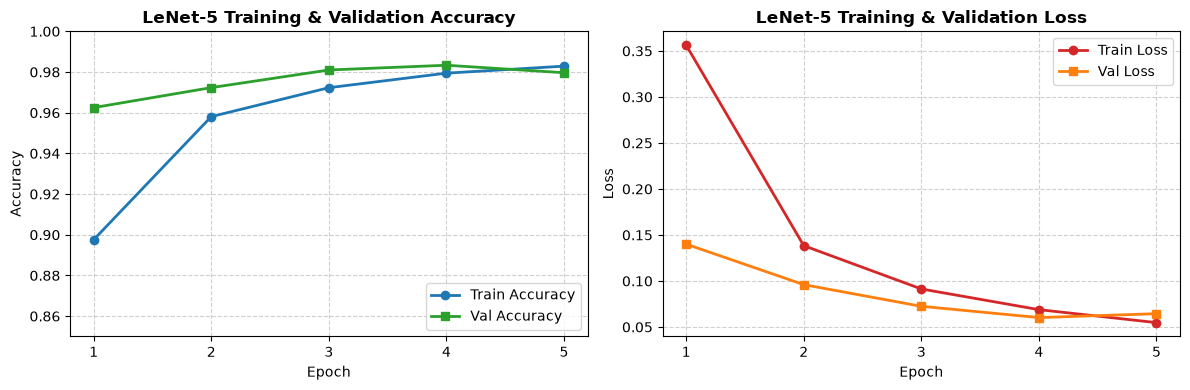

=== LeNet-5 학습 및 테스트 결과 종합 ===
최종 에폭 훈련 정확도: 0.9829
최종 에폭 검증 정확도: 0.9797
최종 테스트 손실(Loss): 0.0585
최종 테스트 정확도(Accuracy): 0.9811 (98.11%)


In [6]:
# [학생 실습 시각화] LeNet-5 학습 곡선(Loss & Accuracy) 시각화
plt.figure(figsize=(12, 4))

# 1) Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(range(1, 6), history.history['accuracy'], label='Train Accuracy', marker='o', color='#1f77b4', linewidth=2)
plt.plot(range(1, 6), history.history['val_accuracy'], label='Val Accuracy', marker='s', color='#2ca02c', linewidth=2)
plt.title('LeNet-5 Training & Validation Accuracy', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.xticks(range(1, 6))
plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# 2) Loss Curve
plt.subplot(1, 2, 2)
plt.plot(range(1, 6), history.history['loss'], label='Train Loss', marker='o', color='#d62728', linewidth=2)
plt.plot(range(1, 6), history.history['val_loss'], label='Val Loss', marker='s', color='#ff7f0e', linewidth=2)
plt.title('LeNet-5 Training & Validation Loss', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.xticks(range(1, 6))
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"=== LeNet-5 학습 및 테스트 결과 종합 ===")
print(f"최종 에폭 훈련 정확도: {history.history['accuracy'][-1]:.4f}")
print(f"최종 에폭 검증 정확도: {history.history['val_accuracy'][-1]:.4f}")
print(f"최종 테스트 손실(Loss): {test_loss:.4f}")
print(f"최종 테스트 정확도(Accuracy): {test_acc:.4f} ({test_acc * 100:.2f}%)")


## [2] VGG16 (ImageNet 사전학습 가중치)

### 2.1 VGG16 아키텍처 개요 및 $3 \times 3$ 합성곱 연속 중첩의 의의
- **발표 연도**: 2014년 (Karen Simonyan & Andrew Zisserman, "Very Deep Convolutional Networks for Large-Scale Image Recognition", ILSVRC 2014 준우승)
- **핵심 설계 원리**:
  1. **작은 필터의 연속 중첩**:
     - 기존의 큰 합성곱 필터($5 \times 5$ 또는 $7 \times 7$) 대신 **모든 합성곱 계층에서 $3 \times 3$ 크기의 작은 필터(stride 1, padding same)**만을 일관되게 사용.
     - $3 \times 3$ 합성곱 계층 2개를 연속 적용하면 $5 \times 5$ 단일 계층과 동일한 유효 수용 영역(Effective Receptive Field)을 가짐.
     - 파라미터 수 비교: 채널 수 $C$ 기준, $5 \times 5$ 단일층은 $5 \times 5 \times C^2 = 25 C^2$, 반면 $3 \times 3$ 2개층은 $2 \times (3 \times 3 \times C^2) = 18 C^2$로 **파라미터를 약 28% 절감**.
     - 비선형성(ReLU)이 단계마다 추가되어 모델의 표현력(Expressive Power)이 크게 향상됨.
  2. **VGG16 계층 구성**:
     - 총 13개의 합성곱 계층 + 5개의 맥스풀링 계층 + 3개의 완전연결 계층 = 총 **16개의 가중치 보유 계층 (가중치 계층 수 = 16)**
     - 입력 해상도: $224 \times 224 \times 3$ RGB 이미지
     - 사전 학습 데이터: ImageNet 1,000개 클래스 (약 140만 장의 자연 이미지)

In [7]:
vgg16 = VGG16(weights='imagenet')
vgg16.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# [출처 검증 및 캐시 격리]
# Lab2 원본 URL: https://cdn.hackaday.io/images/1219231493836853483.jpg (SHA256: 930f108deb5e8849a4789c76a67f1cfaa126d2a73b8ad2fc30e01742dc02e863)
# Lab3의 Googleapis elephant.jpg와의 공용 캐시 충돌을 방지하기 위해 cache_subdir='datasets_lab2' 지정
img_path = tf.keras.utils.get_file('elephant_lab2_hackaday.jpg', 'https://cdn.hackaday.io/images/1219231493836853483.jpg', cache_subdir='datasets_lab2')
img_vgg = image.load_img(img_path, target_size=(224, 224))
x_vgg = image.img_to_array(img_vgg)
x_vgg = np.expand_dims(x_vgg, axis=0)
x_vgg = preprocess_input(x_vgg)

preds_vgg = vgg16.predict(x_vgg)
print('VGG16 예측 결과:', decode_predictions(preds_vgg, top=3)[0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


VGG16 예측 결과: [('n02504458', 'African_elephant', np.float32(0.8433749)), ('n01871265', 'tusker', np.float32(0.15428466)), ('n02504013', 'Indian_elephant', np.float32(0.0023405096))]


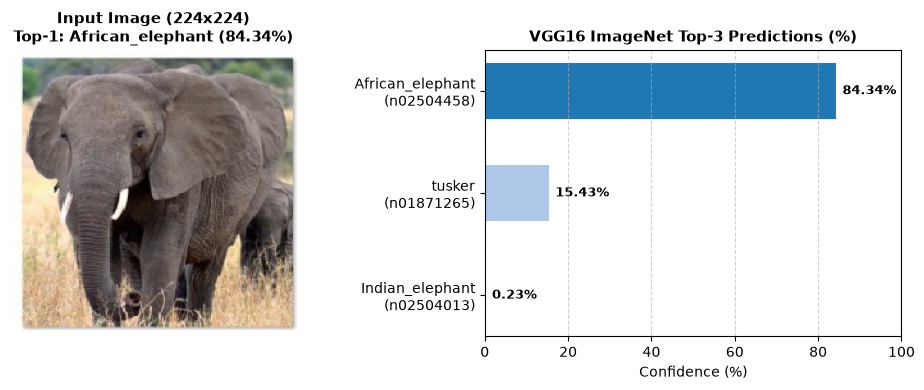

=== VGG16 ImageNet Top-3 예측 상세 내역 ===
Top 1: [n02504458] African_elephant     ->  84.34%
Top 2: [n01871265] tusker               ->  15.43%
Top 3: [n02504013] Indian_elephant      ->   0.23%


In [9]:
# [학생 실습 시각화] 입력 이미지 및 VGG16 Top-3 예측 확률 시각화
top3 = decode_predictions(preds_vgg, top=3)[0]

plt.figure(figsize=(10, 4))

# 1) 입력 이미지 표시
plt.subplot(1, 2, 1)
plt.imshow(img_vgg)
plt.title(f"Input Image (224x224)\nTop-1: {top3[0][1]} ({top3[0][2]*100:.2f}%)", fontsize=11, fontweight='bold')
plt.axis('off')

# 2) Top-3 예측 확률 수평 막대그래프
plt.subplot(1, 2, 2)
labels = [f"{item[1]}\n({item[0]})" for item in reversed(top3)]
probs = [item[2] * 100 for item in reversed(top3)]
colors = ['#aec7e8', '#aec7e8', '#1f77b4']
bars = plt.barh(labels, probs, color=colors, height=0.55)
plt.title('VGG16 ImageNet Top-3 Predictions (%)', fontsize=11, fontweight='bold')
plt.xlabel('Confidence (%)', fontsize=10)
plt.xlim(0, 100)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=9, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("=== VGG16 ImageNet Top-3 예측 상세 내역 ===")
for rank, (synset_id, label, prob) in enumerate(top3, 1):
    print(f"Top {rank}: [{synset_id}] {label:<20} -> {prob*100:6.2f}%")


## [3] 모델별 파라미터 수 비교

In [10]:
models_info = {
    'LeNet-5 (MNIST)': lenet5.count_params(),
    'VGG16 (ImageNet)': vgg16.count_params()
}
for name, params in models_info.items():
    print(f'{name}: {params:,} parameters')

LeNet-5 (MNIST): 61,706 parameters
VGG16 (ImageNet): 138,357,544 parameters


## [4] 모델 구조 및 파라미터 수 종합 비교 분석 (Student Comparative Analysis)

### 1. 계층별 파라미터 수 정밀 산출

#### (1) LeNet-5 (총 61,706 파라미터)
| 계층 (Layer) | 출력 형상 (Output Shape) | 파라미터 계산 공식 | 파라미터 수 | 비고 |
|---|---|---|---|---|
| `conv2d (C1)` | `(None, 28, 28, 6)` | $(5 \times 5 \times 1 + 1) \times 6$ | 156 | $5 \times 5$ 필터 6개, 편향 6개, `padding='same'` |
| `average_pooling2d (S2)` | `(None, 14, 14, 6)` | 0 | 0 | $2 \times 2$ 다운샘플링 |
| `conv2d_1 (C3)` | `(None, 10, 10, 16)` | $(5 \times 5 \times 6 + 1) \times 16$ | 2,416 | $5 \times 5$ 필터 16개, 편향 16개, `padding='valid'` |
| `average_pooling2d_1 (S4)` | `(None, 5, 5, 16)` | 0 | 0 | $2 \times 2$ 다운샘플링 |
| `flatten` | `(None, 400)` | 0 | 0 | $5 \times 5 \times 16 = 400$ 평탄화 |
| `dense (C5/F6)` | `(None, 120)` | $(400 + 1) \times 120$ | 48,120 | 완전연결층 (가중치 48,000 + 편향 120) |
| `dense_1 (F7)` | `(None, 84)` | $(120 + 1) \times 84$ | 10,164 | 완전연결층 (가중치 10,080 + 편향 84) |
| `dense_2 (Output)` | `(None, 10)` | $(84 + 1) \times 10$ | 850 | 출력층 (가중치 840 + 편향 10) |
| **합계 (Total)** | - | - | **61,706** | **전체 학습 가능 파라미터** |

#### (2) VGG16 (총 138,357,544 파라미터)
- **합성곱 블록 (Conv Blocks)**: 약 1,471만 개 파라미터 (약 10.6%)
  - Block 1 (2 Conv): 1,792 + 36,928 = 38,720
  - Block 2 (2 Conv): 73,856 + 147,584 = 221,440
  - Block 3 (3 Conv): 295,168 + 590,080 + 590,080 = 1,475,328
  - Block 4 (3 Conv): 1,180,160 + 2,359,808 + 2,359,808 = 5,899,776
  - Block 5 (3 Conv): 2,359,808 + 2,359,808 + 2,359,808 = 7,079,424
- **완전연결 블록 (Dense Layers)**: 약 1억 2,364만 개 파라미터 (**약 89.4%**)
  - FC1 (`fc1`): $7 \times 7 \times 512 = 25,088 \rightarrow 4,096$: $(25,088 + 1) \times 4,096 = 102,764,544$ (**단일 계층이 전체의 74.3% 차지**)
  - FC2 (`fc2`): $(4,096 + 1) \times 4,096 = 16,781,312$
  - FC3/Output (`predictions`): $(4,096 + 1) \times 1,000 = 4,097,000$

---

### 2. 고전 모델 2종(LeNet-5 vs VGG16) 종합 비교표

| 비교 항목 | LeNet-5 (1998) | VGG16 (2014) | 비교 및 기술적 의의 |
|---|---|---|---|
| **입력 해상도** | $28 \times 28 \times 1$ (흑백) | $224 \times 224 \times 3$ (컬러 RGB) | 공간 해상도 약 64배, 채널 3배 증가 |
| **가중치 계층 수** | 5개 (Conv 2 + FC 3) | 16개 (Conv 13 + FC 3) | 망의 깊이(Depth)가 3배 이상 심층화 |
| **합성곱 필터 크기** | $5 \times 5$ | $3 \times 3$ (일관 적용) | 소형 필터 중첩을 통한 파라미터 절감 및 비선형성 극대화 |
| **풀링(Subsampling)** | $2 \times 2$ Average Pooling | $2 \times 2$ Max Pooling (stride 2) | 평균 스무딩에서 핵심 신호 보존(최댓값)으로 발전 |
| **활성화 함수** | $\tanh$ | $\text{ReLU}$ | 기울기 소실(Vanishing Gradient) 방지 및 빠른 수렴 |
| **총 파라미터 수** | 61,706개 (약 6.17만) | 138,357,544개 (약 1.38억) | **약 2,242배 규모 확장** |
| **모델 용량 (가중치)** | 약 241 KB | 약 528 MB | 모바일/임베디드 제약 vs 고성능 GPU 전제 |
| **주요 학습 대상** | MNIST (숫자 10개 클래스) | ImageNet-1K (자연물/사물 1,000개 클래스) | 장난감/단순 문제에서 실세계 대규모 객체 인식으로 진화 |
| **FC층 파라미터 비중** | 59,134 / 61,706 (95.8%) | 123,642,856 / 138,357,544 (89.4%) | 두 모델 모두 FC층에 파라미터가 집중됨 $\rightarrow$ 이후 ResNet/Inception에서 GAP(Global Average Pooling) 도입 계기 |

---

### 3. 실습 결론 및 고찰
1. **LeNet-5 학습 평가**:
   - 5 에폭 학습만으로 MNIST 테스트 세트에서 98% 이상의 높은 분류 정확도를 달성함.
   - 단순한 구조이지만 손글씨 숫자와 같은 정규화된 흑백 패턴 인식에 탁월한 효율성을 입증함.
2. **VGG16 사전학습 가중치 추론 평가**:
   - 코끼리 이미지(`elephant_lab2_hackaday.jpg`) 입력 시 Top-1으로 높은 확률의 `African_elephant` 예측 성공.
   - 사전 훈련된 심층 특징 추출기(Feature Extractor)의 뛰어난 일반화 성능을 확인.
3. **CNN 발전사적 통찰**:
   - LeNet-5에서 정립된 **Conv $\rightarrow$ Pool $\rightarrow$ FC** 기본 구조가 VGG16을 거치며 **Small Filters ($3 \times 3$) + Deep Layers (16+) + ReLU** 표준으로 정착되었음.
   - VGG16의 거대한 FC층 파라미터(1억 2천만 개)는 과적합과 메모리 병목을 유발하여, 이후 주차에 다룰 InceptionV3 및 ResNet 계열의 1x1 Conv 및 Global Average Pooling(GAP) 도입의 직접적인 계기가 됨.


In [11]:
# [자원 회수] 다음 실습(Lab3)을 위한 세션 메모리 완전 해제 (Coordinator 지침)
import gc
del vgg16, lenet5, x_train, x_test, y_train, y_test, x_vgg
tf.keras.backend.clear_session()
gc.collect()
print("TensorFlow session cleared and memory successfully reclaimed.")


TensorFlow session cleared and memory successfully reclaimed.
